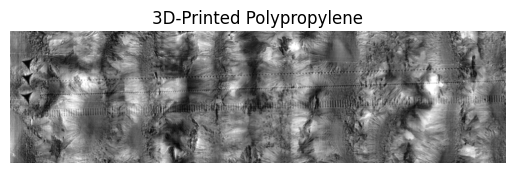

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('3D-Printed Polypropylene.png', cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Erreur: l'image n'a pas pu être chargée.")
else:
    plt.imshow(image, cmap='gray')
    plt.title('3D-Printed Polypropylene')
    plt.axis('off')
    plt.show()

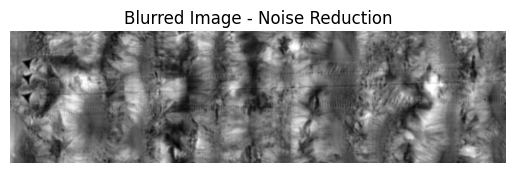

In [11]:
# Apply Gaussian blur to reduce noise
image_blur = cv2.GaussianBlur(image, (5, 5), 0)

# Display the blurred image
plt.imshow(image_blur, cmap='gray')
plt.title('Blurred Image - Noise Reduction')
plt.axis('off')
plt.show()


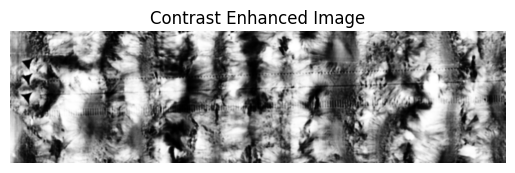

In [12]:
# Enhance contrast using histogram equalization
image_contrast = cv2.equalizeHist(image_blur)

# Display the enhanced contrast image
plt.imshow(image_contrast, cmap='gray')
plt.title('Contrast Enhanced Image')
plt.axis('off')
plt.show()


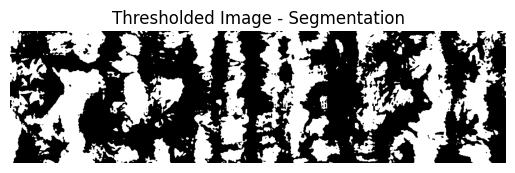

In [13]:
# Apply adaptive thresholding to segment the image
_, image_thresh = cv2.threshold(image_contrast, 150, 255, cv2.THRESH_BINARY)

# Display the thresholded image
plt.imshow(image_thresh, cmap='gray')
plt.title('Thresholded Image - Segmentation')
plt.axis('off')
plt.show()


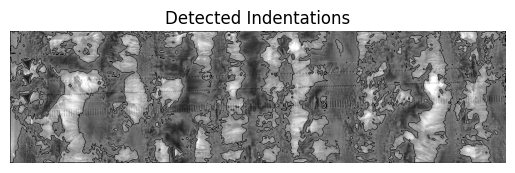

In [14]:
# Find contours on the thresholded image
contours, _ = cv2.findContours(image_thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

# Draw the contours on the original image
image_contours = image.copy()
cv2.drawContours(image_contours, contours, -1, (0, 255, 0), 1)

# Display the image with detected contours
plt.imshow(image_contours, cmap='gray')
plt.title('Detected Indentations')
plt.axis('off')
plt.show()


In [17]:
from skimage.measure import label, regionprops

# Label regions in the thresholded image
label_image = label(image_thresh)

# Display properties of detected indentations
for region in regionprops(label_image):
    if region.area >= 50:  # Filtering based on area
        print(f"Indentation detected at {region.centroid} with area {region.area}")


Indentation detected at (15.370642201834862, 8.124770642201835) with area 545.0
Indentation detected at (22.601003432796407, 122.08053868497491) with area 3787.0
Indentation detected at (3.3055555555555554, 226.29166666666666) with area 72.0
Indentation detected at (28.553323903818953, 333.9694483734088) with area 3535.0
Indentation detected at (114.99421864050456, 403.38086895585144) with area 5708.0
Indentation detected at (91.05913209346686, 506.0717691940868) with area 12582.0
Indentation detected at (18.954179566563468, 644.415479876161) with area 1615.0
Indentation detected at (132.1212417719267, 753.8033268101761) with area 11242.0
Indentation detected at (14.06637168141593, 822.8296460176991) with area 904.0
Indentation detected at (129.24299568965517, 842.9916487068965) with area 7424.0
Indentation detected at (96.86811667085743, 237.62006537591148) with area 7954.0
Indentation detected at (13.06637168141593, 731.3274336283185) with area 226.0
Indentation detected at (26.54634

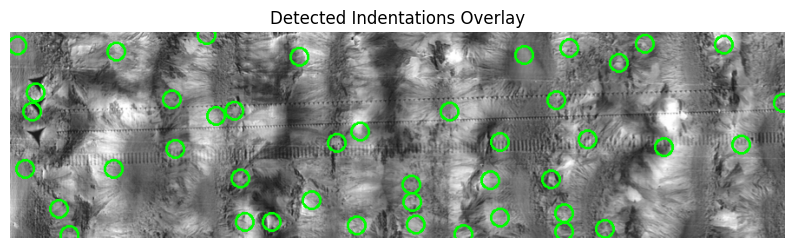

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops

# Load the grayscale image
image = cv2.imread('3D-Printed Polypropylene.png', cv2.IMREAD_GRAYSCALE)

# Apply Gaussian blur to reduce noise
image_blur = cv2.GaussianBlur(image, (5, 5), 0)

# Enhance contrast using histogram equalization
image_contrast = cv2.equalizeHist(image_blur)

# Apply adaptive thresholding to segment the image
_, image_thresh = cv2.threshold(image_contrast, 150, 255, cv2.THRESH_BINARY)

# Find contours on the thresholded image
contours, _ = cv2.findContours(image_thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

# Label regions in the thresholded image
label_image = label(image_thresh)

# Create a color version of the image for display purposes
image_color = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

# Loop through the detected indentations (regions)
for region in regionprops(label_image):
    if region.area >= 50:  # Filter by area size if needed
        # Get the center of the detected indentation
        y, x = region.centroid  # Coordinates in (row, col) format
        
        # Draw a circle on the original image to mark the indentation
        cv2.circle(image_color, (int(x), int(y)), 10, (0, 255, 0), 2)  # Green circles with radius 10

        # Optionally, draw bounding boxes instead of circles
        # minr, minc, maxr, maxc = region.bbox
        # cv2.rectangle(image_color, (minc, minr), (maxc, maxr), (255, 0, 0), 2)  # Red rectangles

# Display the original image with overlaid detected indentations
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image_color, cv2.COLOR_BGR2RGB))  # Convert BGR to RGB for matplotlib
plt.title('Detected Indentations Overlay')
plt.axis('off')
plt.show()


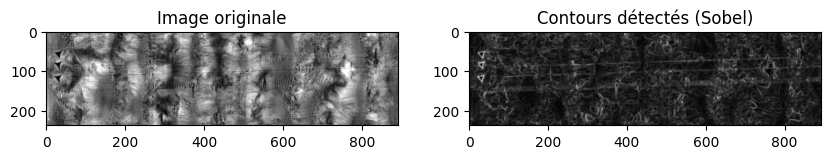

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Charger l'image
image_path = '3D-Printed Polypropylene.png'  # Remplace par ton chemin d'image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Appliquer un filtre Sobel pour détecter les contours
sobelx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=5)  # Gradient en X
sobely = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=5)  # Gradient en Y
sobel_combined = np.sqrt(sobelx**2 + sobely**2)  # Combiner les gradients

# Normaliser l'image pour l'affichage
sobel_combined = cv2.normalize(sobel_combined, None, 0, 255, cv2.NORM_MINMAX)

# Appliquer des filtres morphologiques pour renforcer les indentations
kernel = np.ones((3, 3), np.uint8)
sobel_morph = cv2.morphologyEx(sobel_combined, cv2.MORPH_CLOSE, kernel)

# Affichage du résultat
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Image originale')
plt.imshow(image, cmap='gray')

plt.subplot(1, 2, 2)
plt.title('Contours détectés (Sobel)')
plt.imshow(sobel_morph, cmap='gray')
plt.show()


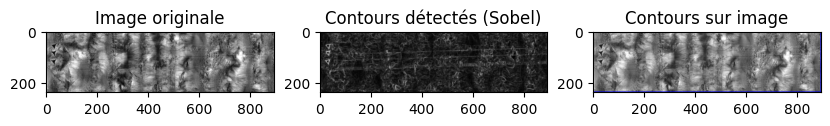

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Charger l'image
image_path = '3D-Printed Polypropylene.png'  # Remplace par ton chemin d'image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Appliquer un filtre Sobel pour détecter les contours
sobelx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=5)  # Gradient en X
sobely = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=5)  # Gradient en Y
sobel_combined = np.sqrt(sobelx**2 + sobely**2)  # Combiner les gradients

# Normaliser l'image pour l'affichage
sobel_combined = cv2.normalize(sobel_combined, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Appliquer une légère érosion/dilatation pour renforcer les traits fins
kernel = np.ones((3, 3), np.uint8)
sobel_morph = cv2.morphologyEx(sobel_combined, cv2.MORPH_CLOSE, kernel)

# Détecter les contours
contours, _ = cv2.findContours(sobel_morph, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Créer une copie de l'image originale pour dessiner les contours dessus
image_with_contours = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)  # Convertir en RGB pour afficher les contours en couleur
cv2.drawContours(image_with_contours, contours, -1, (0, 0, 255), 2)  # Dessiner les contours en rouge

# Afficher le résultat
plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.title('Image originale')
plt.imshow(image, cmap='gray')

plt.subplot(1, 3, 2)
plt.title('Contours détectés (Sobel)')
plt.imshow(sobel_morph, cmap='gray')

plt.subplot(1, 3, 3)
plt.title('Contours sur image')
plt.imshow(image_with_contours)
plt.show()


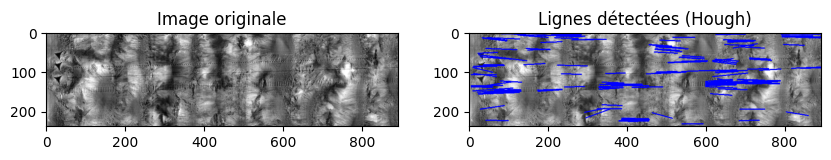

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Charger l'image
image_path = '3D-Printed Polypropylene.png'  # Remplace par ton chemin d'image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Appliquer un léger flou gaussien pour réduire le bruit
blurred = cv2.GaussianBlur(image, (5, 5), 0)

# Appliquer la détection des bords (Canny)
edges = cv2.Canny(blurred, 50, 150, apertureSize=3)

# Utiliser la transformée de Hough pour détecter les lignes
lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=100, minLineLength=50, maxLineGap=10)

# Créer une copie de l'image originale pour dessiner les lignes dessus
image_with_lines = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)  # Convertir en RGB pour dessiner en couleur

# Dessiner les lignes détectées
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(image_with_lines, (x1, y1), (x2, y2), (0, 0, 255), 2)  # Dessiner les lignes en rouge

# Afficher le résultat
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Image originale')
plt.imshow(image, cmap='gray')

plt.subplot(1, 2, 2)
plt.title('Lignes détectées (Hough)')
plt.imshow(image_with_lines)
plt.show()


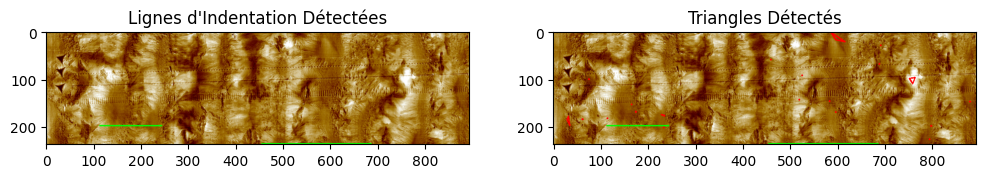

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Charger l'image
image_path = "3D-Printed Polypropylene.png"

image = cv2.imread(image_path)

# Convertir en niveaux de gris
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Appliquer un filtre de Sobel pour détecter les bords
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)
sobel_combined = cv2.sqrt(sobelx**2 + sobely**2)

# Normaliser l'image pour améliorer la visibilité
sobel_combined = cv2.convertScaleAbs(sobel_combined)

# Détection des lignes avec la transformée de Hough
edges = cv2.Canny(sobel_combined, 50, 150)
lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=100, minLineLength=100, maxLineGap=10)

# Dessiner les lignes détectées
line_img = image.copy()
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(line_img, (x1, y1), (x2, y2), (0, 255, 0), 2)

# Détection des formes triangulaires avec approximation des contours
contours, _ = cv2.findContours(edges, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
triangle_img = line_img.copy()
for contour in contours:
    approx = cv2.approxPolyDP(contour, 0.04 * cv2.arcLength(contour, True), True)
    if len(approx) == 3:  # Si la forme a trois côtés, c'est un triangle
        cv2.drawContours(triangle_img, [approx], 0, (0, 0, 255), 2)

# Afficher les résultats
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(line_img, cv2.COLOR_BGR2RGB))
plt.title('Lignes d\'Indentation Détectées')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(triangle_img, cv2.COLOR_BGR2RGB))
plt.title('Triangles Détectés')

plt.show()


In [ ]:
from skimage.io import imread
from skimage.transform import resize
import numpy as np
import matplotlib.pyplot as plt

# Charger l'image fournie (chemin d'accès à ajuster selon ton système)
image_path = "/mnt/data/image.png"
image = imread(image_path, as_gray=True)

# Redimensionner l'image à une taille carrée (par ex., 256x256 pour U-Net)
image_resized = resize(image, (256, 256))

# Afficher l'image originale et redimensionnée
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Image originale')
plt.imshow(image, cmap='gray')

plt.subplot(1, 2, 2)
plt.title('Image redimensionnée')
plt.imshow(image_resized, cmap='gray')
plt.show()


In [ ]:
# Charger le masque binaire correspondant aux indentations
# (Le masque doit avoir la même taille que l'image redimensionnée)
mask_path = "path_to_mask.png"
mask = imread(mask_path, as_gray=True)
mask_resized = resize(mask, (256, 256))

# Afficher l'image et le masque
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Image redimensionnée')
plt.imshow(image_resized, cmap='gray')

plt.subplot(1, 2, 2)
plt.title('Masque binaire des indentations')
plt.imshow(mask_resized, cmap='gray')
plt.show()


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Définir le modèle U-Net
def unet_model(input_size=(256, 256, 1)):
    inputs = layers.Input(input_size)

    # Encoder (partie contractante)
    conv1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    conv1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(conv1)
    pool1 = layers.MaxPooling2D(pool_size=(2, 2))(conv1)

    conv2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(pool1)
    conv2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(conv2)
    pool2 = layers.MaxPooling2D(pool_size=(2, 2))(conv2)

    conv3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(pool2)
    conv3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(conv3)
    pool3 = layers.MaxPooling2D(pool_size=(2, 2))(conv3)

    # Decoder (partie expansive)
    up7 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv3)
    merge7 = layers.concatenate([up7, conv2], axis=3)
    conv7 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(merge7)
    conv7 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(conv7)

    up8 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv7)
    merge8 = layers.concatenate([up8, conv1], axis=3)
    conv8 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(merge8)
    conv8 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(conv8)

    # Dernière couche (Sigmoid pour obtenir un masque binaire)
    conv9 = layers.Conv2D(1, (1, 1), activation='sigmoid')(conv8)

    model = models.Model(inputs=inputs, outputs=conv9)
    
    # Compilation du modèle
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), 
                  loss='binary_crossentropy', metrics=['accuracy'])

    return model

# Création du modèle
model = unet_model(input_size=(256, 256, 1))
model.summary()

# Entraîner le modèle sur l'image redimensionnée et son masque
image_resized = np.expand_dims(image_resized, axis=-1)  # Adapter la forme
mask_resized = np.expand_dims(mask_resized, axis=-1)

X_train = np.expand_dims(image_resized, axis=0)  # Ajouter une dimension pour le batch
Y_train = np.expand_dims(mask_resized, axis=0)

# Entraînement avec un petit dataset (ton image + masque)
history = model.fit(X_train, Y_train, epochs=20, batch_size=1)

# Sauvegarder le modèle
model.save("unet_indentations_model.h5")


In [ ]:
# Prédire le masque pour l'image de test
predicted_mask = model.predict(X_train)

# Afficher le masque prédit
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Image originale redimensionnée')
plt.imshow(image_resized.squeeze(), cmap='gray')

plt.subplot(1, 2, 2)
plt.title('Masque prédit')
plt.imshow(predicted_mask.squeeze(), cmap='gray')
plt.show()


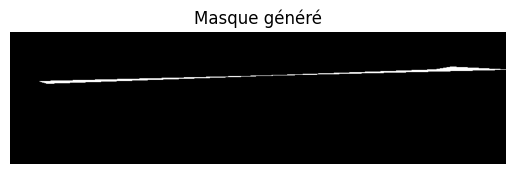

In [52]:
import numpy as np
import cv2
import json
import os
import matplotlib.pyplot as plt

# Charger le fichier JSON généré par LabelMe
json_path = 'C:\\Users\\yelgharo\\OneDrive - ANSYS, Inc\\pythonRepo\\BASF\\3D-Printed Polypropylene_mask.json'
data = json.load(open(json_path))

# Dimensions de l'image originale
height, width = data['imageHeight'], data['imageWidth']

# Créer un masque vide (noir)
mask = np.zeros((height, width), dtype=np.uint8)

# Remplir les zones annotées par des valeurs blanches (255)
for shape in data['shapes']:
    points = np.array(shape['points'], dtype=np.int32)
    cv2.fillPoly(mask, [points], color=(255))

# Sauvegarder le masque binaire
cv2.imwrite('C:\\Users\\yelgharo\\OneDrive - ANSYS, Inc\\pythonRepo\\BASF\\mask.png', mask)

# Afficher le masque
plt.imshow(mask, cmap='gray')
plt.title('Masque généré')
plt.axis('off')  # Ne pas afficher les axes
plt.show()

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9752 - loss: 0.682 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.9752 - loss: 0.6827
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 826ms/step - accuracy: 0.9830 - loss: 0.57 ━━━━━━━━━━━━━━━━━━━━ 1s 832ms/step - accuracy: 0.9830 - loss: 0.5786
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 795ms/step - accuracy: 0.9830 - loss: 0.22 ━━━━━━━━━━━━━━━━━━━━ 1s 801ms/step - accuracy: 0.9830 - loss: 0.2289
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 788ms/step - accuracy: 0.9830 - loss: 0.94 ━━━━━━━━━━━━━━━━━━━━ 1s 793ms/step - accuracy: 0.9830 - loss: 0.9412
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 808ms/step - accuracy: 0.9830 - loss: 0.08 ━━━━━━━━━━━━━━━━━━━━ 1s 813ms/step - accuracy: 0.9830 - loss: 0.0813
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 802ms/step - accuracy: 0.9830 - loss: 0.15 ━━━━━━━━━━━━━━━━━━━━ 1s 807ms/step - accuracy: 0.9830 - loss: 0.1560
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 803ms/step - accuracy: 0.9830 - loss: 0.19 ━━━━━━━━━━━━━━━━━

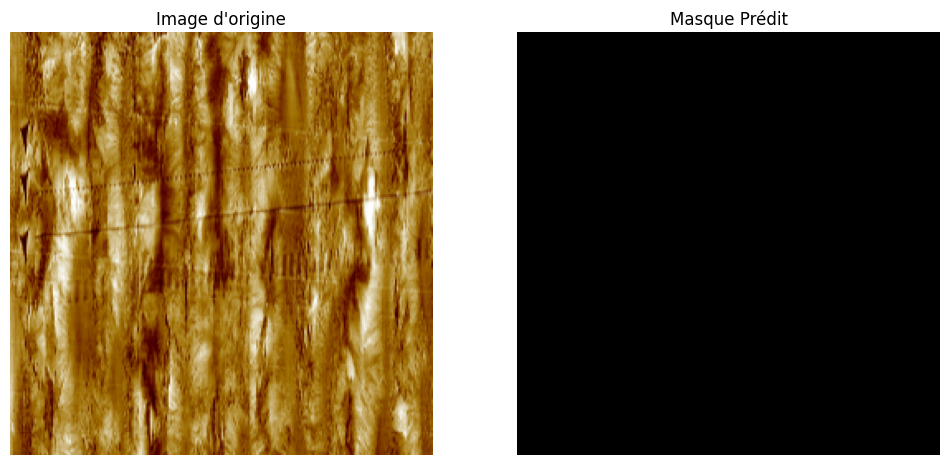

In [65]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
import json

# Chemin de votre image d'origine et du masque
image_path = r'C:\Users\yelgharo\OneDrive - ANSYS, Inc\pythonRepo\BASF\3D-Printed Polypropylene.png'
mask_path = r'C:\Users\yelgharo\OneDrive - ANSYS, Inc\pythonRepo\BASF\mask.png'  # Chemin du masque enregistré

# Charger l'image
image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(f"Image not found at path: {image_path}")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convertir en RGB

# Charger le masque
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)  # Charger en niveau de gris
if mask is None:
    raise FileNotFoundError(f"Mask not found at path: {mask_path}")

# Redimensionner pour l'entrée du modèle (par exemple, 256x256)
image = cv2.resize(image, (256, 256))
mask = cv2.resize(mask, (256, 256))

# Normaliser l'image et préparer le masque
image = image.astype(np.float32) / 255.0  # Normalisation entre 0 et 1
mask = np.expand_dims(mask, axis=-1).astype(np.float32)  # Ajouter une dimension pour le masque
mask = mask / 255.0  # Normalisation

# Fonction pour construire le modèle U-Net
def unet_model(input_shape):
    inputs = layers.Input(shape=input_shape)

    # Encodeur
    c1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(c4)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    c5 = layers.Conv2D(1024, (3, 3), activation='relu', padding='same')(p4)
    c5 = layers.Conv2D(1024, (3, 3), activation='relu', padding='same')(c5)

    # Décodeur
    u6 = layers.Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = layers.concatenate([u6, c4])
    c6 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(c6)

    u7 = layers.Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = layers.concatenate([u7, c3])
    c7 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c7)

    u8 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c7)
    u8 = layers.concatenate([u8, c2])
    c8 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(u8)
    c8 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c8)

    u9 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c8)
    u9 = layers.concatenate([u9, c1])
    c9 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(u9)
    c9 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c9)

    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid')(c9)

    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model

# Créer le modèle
input_shape = (256, 256, 3)  # Taille d'entrée pour le modèle
model = unet_model(input_shape)

# Compiler le modèle
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Entraîner le modèle sur l'image unique
model.fit(np.array([image]), np.array([mask]), epochs=20, batch_size=1)

# Prédictions sur l'image d'origine
predicted_mask = model.predict(np.array([image]))

# Seuil pour obtenir un masque binaire
predicted_mask_binary = (predicted_mask > 0.5).astype(np.uint8)

# Afficher le masque prédit
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(image)  # Affichage direct de l'image normalisée
plt.title('Image d\'origine')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(predicted_mask_binary[0, :, :, 0], cmap='gray')
plt.title('Masque Prédit')
plt.axis('off')

plt.show()
